Training files found: [PosixPath('/kaggle/input/competitions/playground-series-s4e4/train.csv')]
Testing files found: [PosixPath('/kaggle/input/competitions/playground-series-s4e4/test.csv')]
Training shape: (90615, 10)
Testing shape: (60411, 9)

First 5 lines of the training dataset:
   id Sex  Length  Diameter  Height  Whole weight  Whole weight.1  \
0   0   F   0.550     0.430   0.150        0.7715          0.3285   
1   1   F   0.630     0.490   0.145        1.1300          0.4580   
2   2   I   0.160     0.110   0.025        0.0210          0.0055   
3   3   M   0.595     0.475   0.150        0.9145          0.3755   
4   4   I   0.555     0.425   0.130        0.7820          0.3695   

   Whole weight.2  Shell weight  Rings  
0          0.1465        0.2400     11  
1          0.2765        0.3200     11  
2          0.0030        0.0050      6  
3          0.2055        0.2500     10  
4          0.1600        0.1975      9  


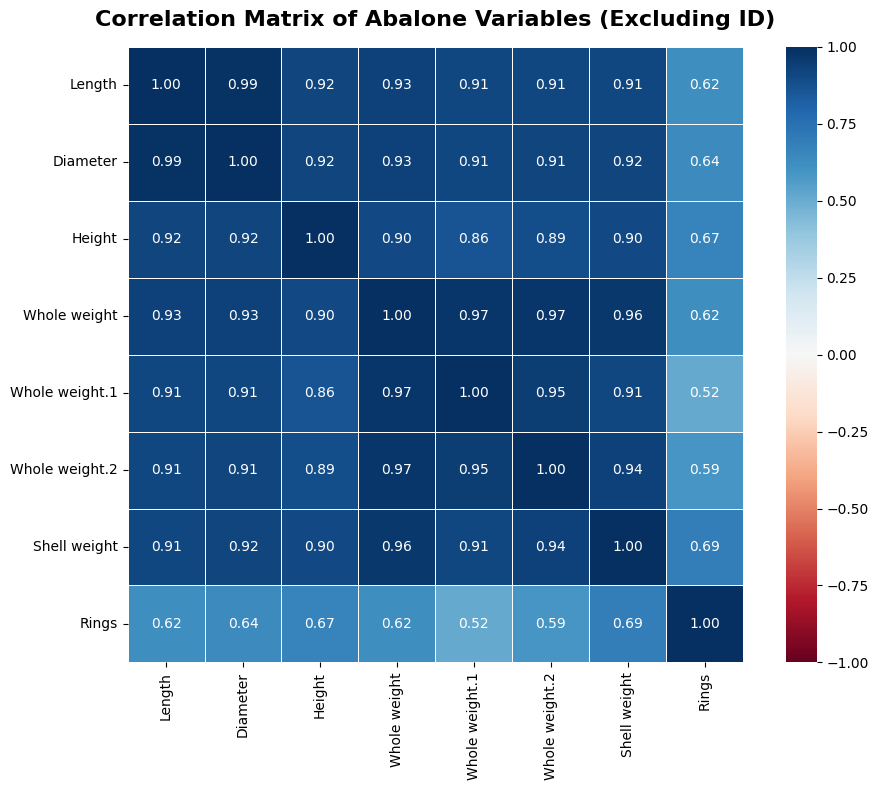


==================== PCA VARIANCE BREAKDOWN ====================
Explained Variance Ratio per Component:
 [0.79669431 0.11530081 0.03809919 0.02127137 0.01311938 0.00821966
 0.00498436 0.00120236 0.00110855]

Cumulative Explained Variance:
 [0.79669431 0.91199512 0.95009431 0.97136568 0.98448506 0.99270473
 0.99768909 0.99889145 1.        ]

############################## RUNNING FULL MODEL (WITH PC2) ##############################

========================= FULL MODEL COEFFICIENT SIGNIFICANCE =========================


,coef,std err,t,P>|t|,[0.025,0.975]
const,9.6971,0.008,1188.826,0.000,9.681,9.713
PC1,0.7679,0.003,252.100,0.000,0.762,0.774
PC2,0.0077,0.008,0.963,0.336,-0.008,0.023
PC3,-0.5268,0.014,-37.820,0.000,-0.554,-0.500
PC4,1.3217,0.019,70.894,0.000,1.285,1.358
PC5,2.1801,0.024,91.840,0.000,2.134,2.227



============================== FULL MODEL ANOVA TABLE ==============================


,df,sum_sq,mean_sq,F,PR(>F)
Model (Regression),5,378365.3053,75673.0611,15689.2681,0.0000e+00
Residual (Error),72486,349617.1699,4.8232,-,-
Total,72491,727982.4751,-,-,-



============================ FULL MODEL PERFORMANCE METRICS ============================


...

,Metric,Reduced Model Value
0,Mean Absolute Error (MAE),1.5186
1,Mean Squared Error (MSE),4.8386
2,Root Mean Squared Log Error (RMSLE),0.1779



============================== INPUT TEST SAMPLE FEATURES ==============================


,Value
Length,0.5500
Diameter,0.4300
Height,0.1500
Whole weight,0.7715
Whole weight.1,0.3285
Whole weight.2,0.1465
Shell weight,0.2400
Sex_I,1.0000
Sex_M,0.0000


Full Model Predicted Rings (with PC2):    10.09
Reduced Model Predicted Rings (no PC2):   10.10

==================== GENERATING KAGGLE SUBMISSION ====================
Training submission pipeline on full dataset utilizing component structure index sequence: [0, 1, 2, 3, 4]


/kaggle/working/submission.csv

In [5]:
# The objective is to predict the number of rings in abalone shells.  
# Model 2 (b) of 2: principal component regression 

# When ready to submit to Kaggle, go to Abalone home page and click Late Submission. 

# =====================================================================
# A. IMPORT THE TOOLS
# =====================================================================
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error
import statsmodels.api as sm
from IPython.display import FileLink

# =====================================================================
# B. LOAD THE FILES
# =====================================================================
input_dir = Path("/kaggle/input")

train_files = list(input_dir.rglob("train.csv"))
test_files = list(input_dir.rglob("test.csv"))

print("Training files found:", train_files)
print("Testing files found:", test_files)

train = pd.read_csv(train_files[0])
test = pd.read_csv(test_files[0])

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

# Display the first 5 lines of the dataset
print("\nFirst 5 lines of the training dataset:")
print(train.head())

# =====================================================================
# C. CORRELATION MATRIX 
# =====================================================================
numeric_train = train.select_dtypes(include=[np.number])
if 'id' in numeric_train.columns:
    numeric_train = numeric_train.drop(columns=['id'])

corr_matrix = numeric_train.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix, 
    annot=True,             
    fmt=".2f",              
    cmap="RdBu",            
    vmin=-1, vmax=1,        
    center=0,               
    square=True,            
    linewidths=0.5          
)
plt.title("Correlation Matrix of Abalone Variables (Excluding ID)", fontsize=16, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# =====================================================================
# D. DATA PREPROCESSING
# =====================================================================
# One-hot encode the categorical 'Sex' column
train_encoded = pd.get_dummies(train, columns=['Sex'], drop_first=True)
test_encoded = pd.get_dummies(test, columns=['Sex'], drop_first=True)

# Align test columns with train columns
test_encoded = test_encoded.reindex(columns=[col for col in train_encoded.columns if col != 'Rings'], fill_value=0)

# Define Features (X) and Target (y)
X = train_encoded.drop(columns=['id', 'Rings'], errors='ignore')
y = train_encoded['Rings']
X_test_final = test_encoded.drop(columns=['id'], errors='ignore')

# Local Train-Validation split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# =====================================================================
# E. STANDARDIZE & APPLY PCA
# =====================================================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_final_scaled = scaler.transform(X_test_final)

pca = PCA()
X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_final_pca = pca.transform(X_test_final_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("\n" + "="*20 + " PCA VARIANCE BREAKDOWN " + "="*20)
print("Explained Variance Ratio per Component:\n", explained_variance)
print("\nCumulative Explained Variance:\n", cumulative_variance)

# =====================================================================
# F. MODEL 1: FULL MODEL (USING TOP 5 COMPONENTS: PC1, PC2, PC3, PC4, PC5)
# =====================================================================
print("\n" + "#"*30 + " RUNNING FULL MODEL (WITH PC2) " + "#"*30)
k_full = 5
full_pcs = list(range(k_full))  # [0, 1, 2, 3, 4]

# Scikit-Learn Model
pcr_full = LinearRegression()
pcr_full.fit(X_train_pca[:, full_pcs], y_train)
val_preds_full = pcr_full.predict(X_val_pca[:, full_pcs])

# Statsmodels Setup
X_train_sm_full = sm.add_constant(X_train_pca[:, full_pcs])
names_full = ['const'] + [f'PC{i+1}' for i in full_pcs]
df_sm_full = pd.DataFrame(X_train_sm_full, columns=names_full, index=y_train.index)
model_sm_full = sm.OLS(y_train, df_sm_full).fit()

# Significance Table Output
print("\n" + "="*25 + " FULL MODEL COEFFICIENT SIGNIFICANCE " + "="*25)
display(model_sm_full.summary().tables[1])

# Manual ANOVA Computation
print("\n" + "="*30 + " FULL MODEL ANOVA TABLE " + "="*30)
ms_mod_f = model_sm_full.ess / model_sm_full.df_model
ms_res_f = model_sm_full.ssr / model_sm_full.df_resid
anova_data_full = {
    "df": [model_sm_full.df_model, model_sm_full.df_resid, model_sm_full.df_model + model_sm_full.df_resid],
    "sum_sq": [model_sm_full.ess, model_sm_full.ssr, model_sm_full.centered_tss],
    "mean_sq": [ms_mod_f, ms_res_f, np.nan],
    "F": [model_sm_full.fvalue, np.nan, np.nan],
    "PR(>F)": [model_sm_full.f_pvalue, np.nan, np.nan]
}
anova_df_full = pd.DataFrame(anova_data_full, index=["Model (Regression)", "Residual (Error)", "Total"])
display(anova_df_full.style.format({"df": "{:.0f}", "sum_sq": "{:.4f}", "mean_sq": "{:.4f}", "F": "{:.4f}", "PR(>F)": "{:.4e}"}, na_rep="-"))

# Metrics Performance Display
print("\n" + "="*28 + " FULL MODEL PERFORMANCE METRICS " + "="*28)
val_mae_f = mean_absolute_error(y_val, val_preds_full)
val_mse_f = mean_squared_error(y_val, val_preds_full)
val_rmsle_f = np.sqrt(mean_squared_log_error(y_val, np.clip(val_preds_full, 0, None)))

metrics_df_full = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Mean Squared Error (MSE)", "Root Mean Squared Log Error (RMSLE)"],
    "Full Model Value": [f"{val_mae_f:.4f}", f"{val_mse_f:.4f}", f"{val_rmsle_f:.4f}"]
})
display(metrics_df_full)

# =====================================================================
# G. MODEL 2: REDUCED MODEL (DROPPING PC2: USING PC1, PC3, PC4, PC5)
# =====================================================================
print("\n" + "#"*30 + " RUNNING REDUCED MODEL (DROPPING PC2) " + "#"*30)
reduced_pcs = [0, 2, 3, 4]  # Slices PC1, PC3, PC4, PC5 out of original matrix arrays

# Scikit-Learn Model
pcr_reduced = LinearRegression()
pcr_reduced.fit(X_train_pca[:, reduced_pcs], y_train)
val_preds_reduced = pcr_reduced.predict(X_val_pca[:, reduced_pcs])

# Statsmodels Setup
X_train_sm_red = sm.add_constant(X_train_pca[:, reduced_pcs])
names_red = ['const', 'PC1', 'PC3', 'PC4', 'PC5']
df_sm_red = pd.DataFrame(X_train_sm_red, columns=names_red, index=y_train.index)
model_sm_red = sm.OLS(y_train, df_sm_red).fit()

# Significance Table Output
print("\n" + "="*25 + " REDUCED MODEL COEFFICIENT SIGNIFICANCE " + "="*25)
display(model_sm_red.summary().tables[1])

# Manual ANOVA Computation
print("\n" + "="*30 + " REDUCED MODEL ANOVA TABLE " + "="*30)
ms_mod_r = model_sm_red.ess / model_sm_red.df_model
ms_res_r = model_sm_red.ssr / model_sm_red.df_resid
anova_data_red = {
    "df": [model_sm_red.df_model, model_sm_red.df_resid, model_sm_red.df_model + model_sm_red.df_resid],
    "sum_sq": [model_sm_red.ess, model_sm_red.ssr, model_sm_red.centered_tss],
    "mean_sq": [ms_mod_r, ms_res_r, np.nan],
    "F": [model_sm_red.fvalue, np.nan, np.nan],
    "PR(>F)": [model_sm_red.f_pvalue, np.nan, np.nan]
}
anova_df_red = pd.DataFrame(anova_data_red, index=["Model (Regression)", "Residual (Error)", "Total"])
display(anova_df_red.style.format({"df": "{:.0f}", "sum_sq": "{:.4f}", "mean_sq": "{:.4f}", "F": "{:.4f}", "PR(>F)": "{:.4e}"}, na_rep="-"))

# Metrics Performance Display
print("\n" + "="*27 + " REDUCED MODEL PERFORMANCE METRICS " + "="*27)
val_mae_r = mean_absolute_error(y_val, val_preds_reduced)
val_mse_r = mean_squared_error(y_val, val_preds_reduced)
val_rmsle_r = np.sqrt(mean_squared_log_error(y_val, np.clip(val_preds_reduced, 0, None)))

metrics_df_red = pd.DataFrame({
    "Metric": ["Mean Absolute Error (MAE)", "Mean Squared Error (MSE)", "Root Mean Squared Log Error (RMSLE)"],
    "Reduced Model Value": [f"{val_mae_r:.4f}", f"{val_mse_r:.4f}", f"{val_rmsle_r:.4f}"]
})
display(metrics_df_red)

# =====================================================================
# H. SAMPLE PREDICTION EXAMPLES (COMPARING BOTH MODELS)
# =====================================================================
new_abalone = {
    'Length': 0.55, 'Diameter': 0.43, 'Height': 0.15,
    'Whole weight': 0.7715, 'Whole weight.1': 0.3285, 'Whole weight.2': 0.1465,
    'Shell weight': 0.24, 'Sex_I': 1, 'Sex_M': 0      
}

sample_df = pd.DataFrame([new_abalone], columns=X.columns)
sample_scaled = scaler.transform(sample_df)
sample_pca = pca.transform(sample_scaled)

print("\n" + "="*30 + " INPUT TEST SAMPLE FEATURES " + "="*30)
display(pd.DataFrame(new_abalone, index=["Value"]).T)

# Predict sample outcomes
pred_sample_full = pcr_full.predict(sample_pca[:, full_pcs])[0]
pred_sample_red = pcr_reduced.predict(sample_pca[:, reduced_pcs])[0]

print(f"Full Model Predicted Rings (with PC2):    {pred_sample_full:.2f}")
print(f"Reduced Model Predicted Rings (no PC2):   {pred_sample_red:.2f}\n")

# =====================================================================
# I. CREATE THE KAGGLE LATE SUBMISSION FILE
# =====================================================================
# Note: This is currently configured to use the full_pcs configuration. 
# If your printed metrics show that dropping PC2 produces a lower local RMSLE, 
# simply switch the two lines below to use: selected_submission_pcs = reduced_pcs
selected_submission_pcs = full_pcs  

print("="*20 + " GENERATING KAGGLE SUBMISSION " + "="*20)
print(f"Training submission pipeline on full dataset utilizing component structure index sequence: {selected_submission_pcs}")

# Display a download link to the generated CSV file
display(FileLink("submission.csv"))